# Programmation Python  pour les mathématiques

**Julien Guillod**, [Sorbonne Université](http://www.sorbonne-universite.fr/),
Licence <a href="https://creativecommons.org/licenses/by-nc-nd/4.0/">CC BY-NC-ND</a>

L'entier des chapitres est disponible au format
[HTML](https://python.guillod.org/) et [PDF](https://python.guillod.org/python.pdf).
Ce notebook peut également être exécuté sur [GESIS](https://notebooks.gesis.org/binder/v2/gh/guillod/python/master?urlpath=lab/tree/chap05.ipynb).

# 5 Intégration

<div id="ch:integration"></div>

Le but est d'obtenir une approximation d'une intégrale définie du type

$$
J = \int_a^b f(x) \, \mathrm{d} x
$$

pour une certaine fonction $f:[a,b] \to \mathbb{R}$ trop compliquée pour *a priori* déterminer la valeur de $J$ à la main.
Des méthodes d'approximations déterministes et probabilistes seront introduites pour obtenir une approximation $\tilde{J}$ de $J$.

**Concepts abordés:**

* méthodes classiques (rectangles, trapèzes et Simpson)

* méthode de Monte-Carlo

* vitesse de convergence

* statistiques

# Exercice 5.1: Méthode des rectangles

<div id="exer:integration-rectangles"></div>

La méthode des rectangles est basée sur la définition de l'intégrale au sens de Riemann. La première étape est de découper l'intervalle $[a,b]$ en $N$ intervalles $[x_n,x_{n+1}]$ de même taille $\delta=\frac{b-a}{N}$, *i.e.* $x_n = a+n\delta$ pour $n\in\{0,1,\dots,N-1\}$. La seconde étape consiste à supposer que la fonction $f$ est constante sur chaque intervalle $[x_n,x_{n+1}]$, donc à faire l'approximation

$$
J_n = \int_{x_n}^{x_{n+1}} f(x) \, \mathrm{d} x \approx \delta f(\tilde{x}_n)
$$

pour $\tilde{x}_n$ une certaine valeur à choisir dans l'intervalle $[x_n,x_{n+1}]$. Le choix de $\tilde{x}_n$ peut par exemple être fait par $\tilde{x}_n = x_n + \alpha\delta$ avec $\alpha\in[0,1]$. Finalement l'approximation de $J$ est donnée par la somme des approximations de $J_n$,

$$
\tilde{J} = \sum_{n=0}^{N-1} \delta f(\tilde{x}_n)\,.
$$

En supposant que $f\in C^1([a,b])$, alors il est possible de montrer que la méthode des rectangles converge et que sa vitesse de convergence est d'ordre un. Une méthode numérique est dite d'ordre $k$ si l'erreur entre l'approximation numérique et le résultat exact est de l'ordre de $N^{-k}$.

**Indication:**
Pour chaque valeur de $n$, et $x\in[x_{n},x_{n+1}]$, par le théorème
des accroissements finis, il existe $c_{n}$ tel que:

$$
f(x)-f(\tilde{x}_{n})=(x-\tilde{x}_{n})f^{\prime}(c_{n})\,.
$$

Si $f^{\prime}$ est continue sur $[a,b]$, alors

$$
\sup_{x\in[a,b]}|f^{\prime}(x)|\leq M\,,
$$

et donc

$$
|f(x)-f(\tilde{x}_{n})|\leq M|x-\tilde{x}_{n}|\leq M\delta\leq\frac{M(b-a)}{N}\,.
$$

Ainsi

$$
\begin{align*}
E_{N} & = \left|\tilde{J}-J\right| = \left|\sum_{n=0}^{N-1}\left(\int_{x_{n}}^{x_{n+1}}f(x)\,\mathrm{d} x-\delta f(\tilde{x}_{n})\right)\right|\\ 
 & \leq\sum_{n=0}^{N-1}\left|\int_{x_{n}}^{x_{n+1}}\left(f(x)-f(\tilde{x}_{n})\right)\,\mathrm{d} x\right|\leq\sum_{n=0}^{N-1}\int_{x_{n}}^{x_{n+1}}|f(x)-f(\tilde{x}_{n})|\,\mathrm{d} x\\ 
 & \leq\sum_{n=0}^{N-1}\int_{x_{n}}^{x_{n+1}}\frac{M(b-a)}{N}\,\mathrm{d} x\leq\frac{M(b-a)^{2}}{N}\,.
\end{align*}
$$

Par conséquent si $f\in C^1([a,b])$, alors la méthode des rectangles est d'ordre un.

**a)**
Choisir une fonction continue $f:[a,b]\to\mathbb{R}$ et définir la fonction Python `f(x)` correspondante. Pour tester le code, il est judicieux de choisir une fonction $f$ dont l'intégrale peut être facilement calculable à la main.

**Indication:**
La liste des fonctions mathématiques de base disponibles en Python dans le module `math` est disponible [ici](https://docs.python.org/fr/3/library/math.html). À noter que Numpy définit également des fonctions mathématiques, voir la documentation [ici](https://numpy.org/doc/stable/reference/routines.math.html).

On s'intéresse à la fonction  $f\in C^1([0,1])$ ,

$$
f(x) = 2x + 3x^2
\\
\int_{0}^{1} f(x)dx  = 2
$$

In [108]:
import numpy as np
def f(x):
    return 2*x + 3*x**2

J = 2 # on reprend la notation J pour l'intégrale 

**b)**
Écrire une fonction `rectangles(f,a,b,N)` qui retourne l'approximation de l'intégrale $J$ par la méthode des rectangles par exemple en choisissant $\tilde{x}_n=x_n$, *i.e.* le bord gauche de l'intervalle $[x_n,x_{n+1}]$.

**Indication:**
Il n'est pas nécessaire de stoker toutes les valeurs des approximations de $J_n$, mais il est possible d'incrémenter une variable pour chaque approximation de $J_n$.

In [109]:
def rectangles(f,a,b,N):
    dx = (b-a)/N
    x = a
    J_approx = 0
    for i in range(N):
        J_approx += dx*f(x)
        x += dx
    return J_approx

In [110]:
# On teste rectangles sur notre fonction f

rectangles(f,0,1,1000)

1.997500500000003

**c)**
Modifier la fonction précédente pour que celle-ci prenne un paramètre optionnel `alpha` déterminant le choix du paramètre $\alpha\in[0,1]$.

In [111]:
def rect_alpha(f,a,b,N,alpha):
    dx = (b-a)/N
    x = a
    J_approx = 0
    for i in range(N):
        J_approx += dx*f(x+alpha*dx)
        x += dx
    return J_approx

In [112]:
rect_alpha(f,0,1,200,0.5)

1.999993750000002

**d)**
Écrire une fonction `plot_rectangles(f,a,b,N,alpha=0.5)` qui représente graphiquement l'approximation par la méthode des rectangles.

In [113]:
import matplotlib.pyplot as plt

def plot_rectangles(f,a,b,N,alpha=0.5):
    plt.figure(figsize =(10,7))
    f_vect = np.vectorize(f)
    dx = (b-a)/N
    
    x = np.linspace(a,b,N+1,endpoint=False)
    x_delta = np.linspace(a+alpha*dx,b+alpha*dx,N+1,endpoint=False)
    y = f_vect(x)

    plt.bar(x,y,width=dx,alpha=alpha,align='edge')
    plt.plot(x_delta,y,'ro--')
    plt.title('Somme de Riemann, N = {}'.format(N))



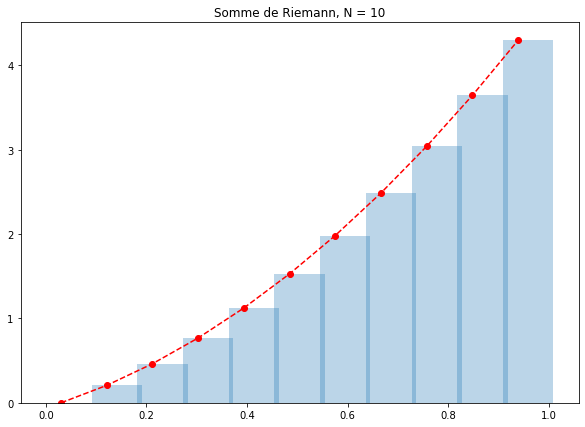

In [114]:
plot_rectangles(f,0,1,10,alpha=0.3)


**e)**
Déterminer empiriquement la vitesse de convergence de la méthode des rectangles en fonction de $N$.

Text(0.5, 0, 'N')

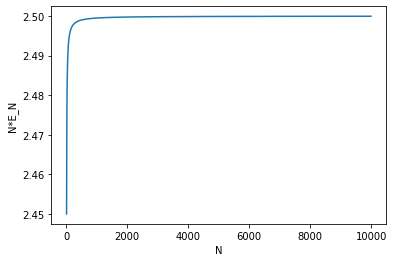

In [115]:
y = np.array([(abs(rectangles(f,0,1,N)-J)*N) for N in range(10,10000,5)])
x = np.arange(10,10000,5)

plt.plot(x,y)
plt.ylabel("N*E_N")
plt.xlabel("N")

# Exercice 5.2: Méthode des trapèzes

<div id="exer:integration-trapezes"></div>

La méthode des trapèzes est basée sur une approximation linéaire sur chaque intervalle $[x_n,x_{n+1}]$, plus spécifiquement:

$$
J_n = \int_{x_n}^{x_{n+1}} f(x) \, \mathrm{d} x \approx \delta \frac{f(x_n) + f(x_{n+1})}{2} \,.
$$

**a)**
Écrire une fonction Python `trapezes(f,a,b,N)` qui retourne l'approximation de l'intégrale $J$ par la méthode des trapèzes. Tester la fonction `trapezes(f,a,b,N)` pour différentes fonctions $f$.

In [116]:
def trapezes(f,a,b,N):
    
    dx = (b-a)/N
    x = a
    J_approx = 0
    for i in range(N):
        #on rappelle que x_(n+1) = x + dx
        J_approx += dx*(f(x)+f(x+dx))/2
        x += dx
    return J_approx
    

In [117]:
def h(x) :
    return np.cos(x) - np.sin(x)

def tanh(x):
    return (np.exp(x)-np.exp(-x))/(np.exp(x)+np.exp(-x))


In [118]:
# sinh, une fonction impaire, donc tout intégrale de tanh sur un intervalle centré en 0 sera nulle

trapezes(tanh,-1,1,10000)

-1.1838850754765373e-13

**b)**
L'implémentation de votre fonction `trapezes(f,a,b,N)` est-elle optimale quant au nombre d'évaluations de $f$ effectuées par rapport au nombre d'évaluations nécessaires ? Une implémentation optimale de la fonction `trapezes(f,a,b,N)` devrait effectuer $N+1$ évaluations de $f$.

L'intégrale est égale à

$$
\sum_{n=0}^{N}J_n = \sum_{n=0}^{N} \int_{x_n}^{x_{n+1}} f(x) \, \mathrm{d} x \approx \sum_{n=0}^{N}\delta \frac{f(x_n) + f(x_{n+1})}{2} \
$$

En réordonnant les termes de la somme on  a

$$
\sum_{n=0}^{N}J_n \approx \delta \frac{f(x_0) + f(x_{N+1})}{2} + \delta\sum_{n=1}^{N} f(x_n) = \delta [\frac{f(x_0) + f(x_{N+1})}{2} + \sum_{n=1}^{N} f(x_n)]
$$

On définit une autre fonction trapezes_opt plus efficace en utilisant cette somme et en la vectorisant pour gagner en temps de calcul

In [119]:
def trapezes_opt(f, a, b, N):
    dx = (b - a) / N
    # Premiere Partie : On fait la moyenne du 1er et dernier termes
    J_approx = (f(a) + f(b)) / 2

    # On génère un vecteur de points qui va servir au second terme de notre somme
    x = np.linspace(a + dx, b - dx, N - 1)
    J_approx += np.sum(f(x))

    # On multiplie le tout par delta
    return J_approx * dx


**c)**
Déterminer empiriquement la vitesse de convergence de la méthode des trapèzes en fonction de $N$.

In [120]:
# On reprend notre fonction f définie en Question 1 de  l'exercice 1

import numpy as np
def f(x):
    return 2*x + 3*x**2

J = 2 # on reprend la notation J pour l'intégrale entre 0 et 1

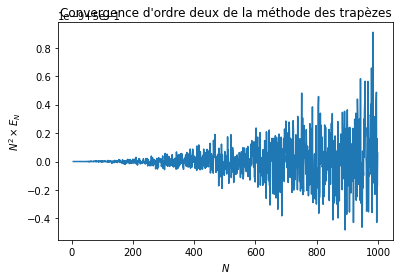

In [121]:
# On définit une fonction qui garde les autres variables constantes et modifie la variable en paramètre afin de pouvoir la vectorizer sur la variable N par la suite.
def trapezes_f_N(N):
    return trapezes_opt(f,0,1,N)

N_v  = np.arange(5,1000)
v_trapeze = np.vectorize(trapezes_f_N)

plt.title("Convergence d'ordre deux de la méthode des trapèzes") 
plt.xlabel(r"$N$")
plt.ylabel(r"$N^2 \times E_N$") 
plt.plot(N_v, np.abs(2-v_trapeze(N_v))*N_v**2)


### La courbe semble rester centrée autour de l'axe des abscisses, et l'on peut en déduire que la méthode est d'ordre 2

**d)**
<span style="color:red">!</span> Déterminer analytiquement la convergence de la méthode des trapèzes. Quelles sont les hypothèses nécessaires sur $f$ ?

# Exercice 5.3: Méthode de Monte-Carlo

<div id="exer:integration-montecarlo"></div>

La méthode de Monte-Carlo (du nom des casinos, pas d'une personne) est une approche probabiliste permettant d'approximer la valeur d'une intégrale. L'idée de base est que l'intégrale $J$ peut être vue comme l'espérance d'une variable aléatoire uniforme $X$ sur l'intervalle $[a,b]$:

$$
J = \int_a^b f(x) \, \mathrm{d} x = (b-a)\mathbb{E}(f(X)) \,.
$$

Par la loi des grands nombres cette espérance peut être approximée par la moyenne empirique:

$$
\tilde{J} = \frac{b-a}{N}\sum_{i=0}^{N-1} f(x_i) \,,
$$

où les $x_i$ sont tirés aléatoirement dans l'intervalle $[a,b]$ avec une loi de probabilité uniforme.

Il est possible de montrer que $\tilde{J}$ converge vers $J$ comme $N^{-1/2}$ et cela indépendamment de la dimension et de la régularité de $f$.

**Indication:**
Selon le théorème central limite, si $Y_i$ est une suite de variables aléatoires indépendantes d'espérance $\mu$ et de variance $\sigma^2$, alors la variable aléatoire:

$$
S_N = \frac{1}{N}\sum_{i=0}^{N-1} Y_i \,,
$$

a une espérance $\mu$ et une variance:

$$
\mathrm{Var}(S_N) = \frac{\sigma^2}{N} \,.
$$

En prenant $Y_i=f(X_i)$ avec $X_i$ une suite de variables aléatoires indépendantes uniformément distribuées sur $[a,b]$, alors l'espérance de $Y_i$ est la moyenne de $f$ et donc l'espérance de $S_N$ est donnée par:

$$
\mathbb{E}(S_N) = \frac{1}{b-a} \int_a^b f(x) \, \mathrm{d} x \,.
$$

La variance de $Y_i$ est également celle de $f$, $\sigma^2 = \mathrm{Var}(f(X))$ et donc la variance de $S_N$ est:

$$
\mathrm{Var}(S_N) = \frac{\mathrm{Var}(f(X))}{N} \,.
$$

Par conséquent, cela montre que $\tilde{J}$ converge vers $J$ comme $N^{-1/2}$ vu que la variance est proportionnelle à $N^{-1}$.

A remarquer que pour établir ce résultat, aucune condition de régularité sur $f$ n'est nécessaire, de l'intégrabilité suffit.

En pratique la variance de $f$ peut être estimée par la variance empirique.

**a)**
Écrire une fonction `montecarlo(f,a,b,N)` qui détermine une approximation $\tilde{J}$ de $J$ par la méthode de Monte-Carlo.

**Indication:**
Pour générer un vecteur de nombres aléatoires, le sous-module `random` de Numpy peut être utile, voir la documentation [ici](https://numpy.org/doc/stable/reference/random/index.html).

In [122]:
def montecarlo(f,a,b,N):
    # Genere des nombres aleatoires entre a et b
    x = np.random.uniform(a,b,N)
    
    # Vectorize f
    v_f = np.vectorize(f)
    
    return np.sum(v_f(x))*(b-a)/N

**b)**
Modifier la fonction précédente, pour qu'elle retourne en plus de la moyenne $\tilde{J}$ également la variance empirique:

$$
\tilde{V} = \frac{(b-a)^2}{N}\sum_{i=0}^{N-1} \left(f(x_i)-\frac{\tilde{J}}{b-a}\right)^2 \,.
$$

In [132]:
def montecarlo_2(f,a,b,N):
    # Vectorize f
    v_f = np.vectorize(f)
    
    # Genere des nombres aleatoires entre a et b
    x = np.random.uniform(a,b,N)
    y =  v_f(x)
    
    # Nos outputs
    J_tilde = np.mean(y)*(b-a)/N
    V_tilde = np.sum((y - J_tilde/(b-a))**2)*(b-a)**2 / N
    return (J_tilde,V_tilde)


**c)**
Étudier empiriquement la convergence de la méthode de Monte-Carlo en fonction de $N$ en faisant pour chaque valeur de $N$ une statistique sur $k$ exécutions. Plus précisément cela consiste à faire $k$ évaluations de $\tilde{J}$ par la méthode de Monte-Carlo et de calculer la moyenne et la variance des $k$ résultats obtenus.

In [124]:


def emp_test_MC(f,a,b,N,k):
    """
    Parameters:
    f (Fonction): Fonction étudiée
    a (float): début de l'intervalle duquel on génère des variables aléatoires
    b (float): fin de l'intervalle duquel on génère des variables aléatoires
    N (int): N maximal
    k (int): nombre de simulations de monte carlo
    """
    def mc_f(N_2):
        return montecarlo_2(f,a,b,N_2)
    
    v_mc_f = np.vectorize(mc_f)
    
    v_N = np.arange(1,N+1)
    
    return np.array(map(lambda N : np.mean(np.vstack(mc_f(np.full(k,N))), axis=1),v_N))
    
    


# Exercice 5.4: <span style="color:red">!</span> Méthode de Simpson

<div id="exer:integration-simpson"></div>

La méthode de Simpson consiste à approximer la fonction $f$ sur chaque intervalle $[x_n,x_{n+1}]$ par un polynôme de degré deux. Le choix le plus naturel est le polynôme $p_n$ de degré deux passant par les points $(x_n,f(x_n))$, $(\frac{x_n+x_{n+1}}{2},f(\frac{x_n+x_{n+1}}{2}))$ et $(x_{n+1},f(x_{n+1}))$.

**a)**
Déterminer la forme explicite du polynôme $p_n$.

**Indication:**
Le polynôme $L(x) = \frac{(x-c)(x-b)}{(a-c)(a-b)}$ prend la valeur 1 en $x=a$ et la valeur 0 en $x=b$ et $x=c$. Faire une combinaison linéaire de trois polynômes de ce type.

**b)**
Calculer l'approximation donnée par $J_n \approx \int_{x_n}^{x_{n+1}} p_n(x)\,\mathrm{d} x \,.$

**Indication:**
Il est possible de calculer cette intégrale à la main ou bien de le faire avec le module Sympy, voir la documentation [ici](https://docs.sympy.org/latest/modules/integrals/integrals.html).

**c)**
Simplifier à la main la somme $\tilde{J}$ des approximations de $J_n$.

**Réponse:**
Le résultat est:

$$
\tilde{J} = \frac{\delta}{3}\left[\frac{f(b)-f(a)}{2}+\sum_{n=0}^{N-1}\left(f(x_{n})+2f\left(\frac{x_{n}+x_{n+1}}{2}\right)\right)\right] \,.
$$


**d)**
Écrire une fonction `simpson(f,a,b,N)` permettant de calculer une approximation de $J$ avec la méthode de Simpson.



**e)**
Comparer la précision des méthodes des rectangles, des trapèzes et de Simpson en fonction de $N$ pour une fonction lisse et la fonction $f(x)=\sqrt{1-x^2}$ sur $[0,1]$ (dont l'intégrale vaut $\frac{\pi}{4}$).

**f)**
Si ce n'est pas déjà fait proposer une implémentation parallèle de la méthode de Simpson en utilisant l'indexage Numpy.

# Exercice 5.5: <span style="color:red">!!</span> Intégration avec Scipy

Les méthodes d'intégrations précédentes et d'autres sont définies dans le module `integrate` de Scipy. Ce module permet en particulier de traiter des cas plus compliqués: intégrales singulières, généralisées ou en plusieurs dimensions.

**a)**
Définir une fonction `E(n,x)` calculant numériquement l'intégrale suivante:

$$
E_n(x) = \int_1^\infty \frac{e^{-xt}}{t^n} \mathrm{d} t \,.
$$

**Indication:**
Lire la documentation du sous-module `integrate` de Scipy disponible [ici](https://docs.scipy.org/doc/scipy/tutorial/integrate.html).

**b)**
Déterminer une approximation de l'intégrale double:

$$
I = \int_{0}^{\pi} \left(\int_{0}^{y} x \sin(xy) \,\mathrm{d} x \right) \mathrm{d} y \,.
$$